# Data Cleaning Player stats


In [ ]:
import os
import urllib.request
import pandas as pd

os.makedirs('data/00-raw', exist_ok=True)

reg_path = 'data/00-raw/nba_regular_season_2016_2026.csv'
po_path = 'data/00-raw/nba_playoffs_2016_2026.csv'

DB_URL = "https://basketball-data.billmill.org/nba/nba.duckdb"

def fetch_nba_dataset(con, season_type):
    """season_type: 'regular_season' or 'playoffs'. Returns one row per player-season (2015-16 to 2025-26)."""
    query = f"""
    WITH first_season AS (
        -- each player's first regular-season year in the DB (same for both tables)
        SELECT player_id, MIN(season) AS first_season
        FROM player_season_stats_per_game
        WHERE season_type = 'regular_season'
        GROUP BY player_id
    ),
    dedup_stats AS (
        SELECT
            s.player_id,
            p.name AS player_name,
            s.season,
            MAX(s.age) AS age,
            -- rookie season = 1. Drafted: season - draft_year. Undrafted: counted from first regular season.
            s.season - COALESCE(MAX(s.draft_year), MAX(f.first_season) - 1) AS years_in_nba,
            MAX(s.draft_year) IS NULL AS years_in_nba_estimated,
            SUM(s.gp) AS gp,
            SUM(s.min * s.gp) / NULLIF(SUM(s.gp), 0) AS mpg,
            SUM(s.pts * s.gp) / NULLIF(SUM(s.gp), 0) AS ppg,
            SUM(s.reb * s.gp) / NULLIF(SUM(s.gp), 0) AS rpg,
            SUM(s.ast * s.gp) / NULLIF(SUM(s.gp), 0) AS apg,
            SUM(s.blk * s.gp) / NULLIF(SUM(s.gp), 0) AS bpg,
            SUM(s.stl * s.gp) / NULLIF(SUM(s.gp), 0) AS spg,
            SUM(s.plus_minus * s.gp) / NULLIF(SUM(s.gp), 0) AS plus_minus,
            SUM(s.ts_pct * s.gp) / NULLIF(SUM(s.gp), 0) AS ts_pct
        FROM player_season_stats_per_game s
        JOIN players p ON s.player_id = p.player_id
        LEFT JOIN first_season f ON s.player_id = f.player_id
        WHERE s.season BETWEEN 2014 AND 2026
          AND s.season_type = '{season_type}'
        GROUP BY s.player_id, p.name, s.season
    ),
    with_trends AS (
        SELECT
            *,
            (COUNT(*) OVER w3 = 3 AND MAX(season) OVER w3 - MIN(season) OVER w3 = 2) AS full_3yr_window,
            AVG(ppg) OVER w3 AS trend_3yr_ppg,
            AVG(rpg) OVER w3 AS trend_3yr_rpg,
            AVG(apg) OVER w3 AS trend_3yr_apg,
            AVG(plus_minus) OVER w3 AS trend_3yr_pm,
            AVG(mpg) OVER w3 AS trend_3yr_mpg,
            AVG(gp) OVER w3 AS trend_3yr_gp
        FROM dedup_stats
        WINDOW w3 AS (
            PARTITION BY player_id
            ORDER BY season
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        )
    )
    SELECT
        season, player_id, player_name, age, years_in_nba, years_in_nba_estimated, gp,
        ROUND(mpg, 2) AS mpg, ROUND(ppg, 2) AS ppg, ROUND(rpg, 2) AS rpg,
        ROUND(apg, 2) AS apg, ROUND(bpg, 2) AS bpg, ROUND(spg, 2) AS spg,
        ROUND(plus_minus, 2) AS plus_minus, ROUND(ts_pct, 4) AS ts_pct,
        full_3yr_window,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_ppg, 2) END AS trend_3yr_ppg,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_rpg, 2) END AS trend_3yr_rpg,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_apg, 2) END AS trend_3yr_apg,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_pm, 2) END AS trend_3yr_pm,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_mpg, 2) END AS trend_3yr_mpg,
        CASE WHEN full_3yr_window THEN ROUND(trend_3yr_gp, 2) END AS trend_3yr_gp
    FROM with_trends
    WHERE season BETWEEN 2016 AND 2026
    ORDER BY season DESC, ppg DESC;
    """
    return con.sql(query).df()

def build_csvs():
    """Only runs when the CSVs are missing: download the database temporarily, save the CSVs, delete the database."""
    import duckdb
    tmp_db = 'nba_tmp.duckdb'
    print('CSV files not found. Downloading the database once (it is deleted afterwards)...')
    urllib.request.urlretrieve(DB_URL, tmp_db)
    con = duckdb.connect(tmp_db, read_only=True)
    try:
        print(con.sql("DESCRIBE player_season_stats_per_game").df()[['column_name', 'column_type']])
        fetch_nba_dataset(con, 'regular_season').to_csv(reg_path, index=False)
        fetch_nba_dataset(con, 'playoffs').to_csv(po_path, index=False)
    finally:
        con.close()
        os.remove(tmp_db)

if not (os.path.exists(reg_path) and os.path.exists(po_path)):
    build_csvs()

df_regular = pd.read_csv(reg_path)
df_playoffs = pd.read_csv(po_path)
print(df_regular.shape, df_playoffs.shape)
print(df_regular['years_in_nba'].isna().sum(), df_playoffs['years_in_nba'].isna().sum())



CSV files not found. Downloading the database once (it is deleted afterwards)...
     column_name column_type
0         season     INTEGER
1    season_type     VARCHAR
2      player_id     VARCHAR
3        team_id     VARCHAR
4            age      DOUBLE
..           ...         ...
84       country     VARCHAR
85    draft_year     INTEGER
86   draft_round     INTEGER
87  draft_number     INTEGER
88       college     VARCHAR

[89 rows x 2 columns]


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(5968, 22) (2405, 22)
0 1


In [ ]:
df_regular.head()

,season,player_id,player_name,age,years_in_nba,years_in_nba_estimated,gp,mpg,ppg,rpg,...,spg,plus_minus,ts_pct,full_3yr_window,trend_3yr_ppg,trend_3yr_rpg,trend_3yr_apg,trend_3yr_pm,trend_3yr_mpg,trend_3yr_gp
0,2026,1629029,Luka Dončić,27.0,8,False,64.0,35.76,33.48,7.73,...,1.64,2.92,0.616,True,31.83,8.39,8.58,4.79,36.21,61.33
1,2026,1628983,Shai Gilgeous-Alexander,27.0,8,False,68.0,33.22,31.13,4.29,...,1.40,11.59,0.665,True,31.29,4.94,6.39,10.61,33.81,73.00
2,2026,1630162,Anthony Edwards,24.0,6,False,61.0,35.03,28.80,4.95,...,1.36,2.66,0.617,True,27.43,5.36,4.46,3.94,35.48,73.00
3,2026,1627759,Jaylen Brown,29.0,10,False,71.0,34.41,28.70,6.93,...,1.01,4.52,0.573,True,24.63,6.10,4.41,5.60,34.04,68.00
4,2026,1630178,Tyrese Maxey,25.0,6,False,70.0,38.02,28.29,4.14,...,1.86,1.61,0.588,True,26.85,3.72,6.29,1.19,37.74,64.00


In [ ]:
df_playoffs.head()

,season,player_id,player_name,age,years_in_nba,years_in_nba_estimated,gp,mpg,ppg,rpg,...,spg,plus_minus,ts_pct,full_3yr_window,trend_3yr_ppg,trend_3yr_rpg,trend_3yr_apg,trend_3yr_pm,trend_3yr_mpg,trend_3yr_gp
0,2026,1628973,Jalen Brunson,29.0,8.0,False,19.0,36.92,28.37,3.16,...,1.21,12.32,0.573,True,30.07,3.30,6.84,4.45,38.17,16.67
1,2026,1630595,Cade Cunningham,24.0,5.0,False,14.0,40.82,28.14,5.14,...,1.07,2.43,0.572,False,NaN,NaN,NaN,NaN,NaN,NaN
2,2026,1628983,Shai Gilgeous-Alexander,27.0,8.0,False,15.0,36.28,27.60,2.93,...,1.27,2.60,0.591,True,29.24,5.16,6.95,5.14,37.71,16.00
3,2026,1631094,Paolo Banchero,23.0,4.0,False,7.0,39.02,26.29,9.00,...,1.43,-2.43,0.524,True,27.56,8.66,4.83,-2.26,38.64,6.33
4,2026,1628415,Dillon Brooks,30.0,9.0,False,4.0,37.32,26.00,6.00,...,0.25,-7.50,0.576,False,NaN,NaN,NaN,NaN,NaN,NaN


### 3B. Is this data tidy?
We will inspect the structure of `df_regular` to verify if it is tidy, check for duplicate player-season pairs, confirm data types, and ensure column names are in lowercase.

In [ ]:
print("--- Dataframe Info ---")
df_regular.info()

# Check for duplicated player-season pairs
duplicate_pairs = df_regular.duplicated(subset=['player_id', 'season']).sum()
print(f"\nNumber of duplicate (player_id, season) pairs: {duplicate_pairs}")

# Check if column names are lowercase
columns_are_lowercase = df_regular.columns.tolist() == [c.lower() for c in df_regular.columns]
print(f"Are all columns lowercase? {columns_are_lowercase}")
if not columns_are_lowercase:
    df_regular.columns = [c.lower() for c in df_regular.columns]
    print("Converted columns to lowercase.")

--- Dataframe Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5968 entries, 0 to 5967
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   season                  5968 non-null   int64  
 1   player_id               5968 non-null   int64  
 2   player_name             5968 non-null   object 
 3   age                     5968 non-null   float64
 4   years_in_nba            5968 non-null   int64  
 5   years_in_nba_estimated  5968 non-null   bool   
 6   gp                      5968 non-null   float64
 7   mpg                     5968 non-null   float64
 8   ppg                     5968 non-null   float64
 9   rpg                     5968 non-null   float64
 10  apg                     5968 non-null   float64
 11  bpg                     5968 non-null   float64
 12  spg                     5968 non-null   float64
 13  plus_minus              5968 non-null   float64
 14  ts_pct           

### What we found
* **Tidiness**: The data is tidy! Each row represents a single player's performance in a single regular season, and each column represents a single attribute.
* **Duplicates**: There are 0 duplicate (player_id, season) pairs, confirming that each player has exactly one record per season.
* **Column names**: The column names are already in lowercase (e.g., `season`, `player_id`, `player_name`, etc.).

### 3C. Size of the data
We will now print key metrics describing the dataset's size, season range, player count, and games played (`gp`) distribution.

In [ ]:
num_rows, num_cols = df_regular.shape
min_season = df_regular['season'].min()
max_season = df_regular['season'].max()
num_players = df_regular['player_id'].nunique()
rows_per_season = df_regular['season'].value_counts().sort_index()

gp_min = df_regular['gp'].min()
gp_median = df_regular['gp'].median()
gp_max = df_regular['gp'].max()

print(f"Dataset Shape: {num_rows} rows, {num_cols} columns")
print(f"Season Range: {min_season} to {max_season}")
print(f"Number of Unique Players: {num_players}")
print("\nRows per Season:")
print(rows_per_season)
print(f"\nGames Played (gp) - Min: {gp_min}, Median: {gp_median}, Max: {gp_max}")

Dataset Shape: 5968 rows, 22 columns
Season Range: 2016 to 2026
Number of Unique Players: 1554

Rows per Season:
season
2016    476
2017    486
2018    540
2019    530
2020    529
2021    540
2022    605
2023    539
2024    572
2025    569
2026    582
Name: count, dtype: int64

Games Played (gp) - Min: 1.0, Median: 53.0, Max: 84.0


### What we found
- **Rows and columns:** The raw regular-season table has 5,968 rows and 22 columns.
- **Seasons and players:** It covers 2016 to 2026 (2015-16 to 2025-26) with 1,554 different players.
- **Games played:** Players played from 1 to 84 games, and the middle value is 53. Many players have very few games, which is why we filter on `gp` in 3F.

### 3D. Missing data analysis
We will look for missing values across all columns and check how many of these missing values are expected due to rolling trend calculations.

In [ ]:
print("--- Missing values per column ---")
print(df_regular.isna().sum())

# Check gp == 0 or mpg == 0
gp_zero = (df_regular['gp'] == 0).sum()
mpg_zero = (df_regular['mpg'] == 0).sum()
print(f"\nRows with gp == 0: {gp_zero}")
print(f"Rows with mpg == 0: {mpg_zero}")

# Gaps from rolling average window
no_window_count = (df_regular['full_3yr_window'] == False).sum()
trend_nan_count = df_regular['trend_3yr_ppg'].isna().sum()
non_trend_nans = df_regular.drop(columns=[c for c in df_regular.columns if 'trend_3yr' in c]).isna().sum().sum()

print(f"Rows where full_3yr_window is False: {no_window_count}")
print(f"Rows where trend_3yr_ppg is NaN: {trend_nan_count}")
print(f"Total NaNs in non-trend columns: {non_trend_nans}")

--- Missing values per column ---
season                       0
player_id                    0
player_name                  0
age                          0
years_in_nba                 0
years_in_nba_estimated       0
gp                           0
mpg                          0
ppg                          0
rpg                          0
apg                          0
bpg                          0
spg                          0
plus_minus                   0
ts_pct                       0
full_3yr_window              0
trend_3yr_ppg             2191
trend_3yr_rpg             2191
trend_3yr_apg             2191
trend_3yr_pm              2191
trend_3yr_mpg             2191
trend_3yr_gp              2191
dtype: int64

Rows with gp == 0: 0
Rows with mpg == 0: 0
Rows where full_3yr_window is False: 2191
Rows where trend_3yr_ppg is NaN: 2191
Total NaNs in non-trend columns: 0


### What we found
- **Expected missing values:** 2,191 rows have `full_3yr_window == False`, and this matches the 2,191 missing values in each `trend_3yr_*` column. They are missing on purpose, because these players (rookies, second-year players, or players with a gap in seasons) do not have 3 seasons in a row.
- **Everything else is complete:** The non-trend columns have 0 missing values, and no row has 0 games or 0 minutes per game.

### 3E. Outliers and suspicious entries
We will define a custom helper to flag outliers within each season using the Interquartile Range (IQR) rule and inspect suspicious values.

In [ ]:
def flag_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return (series < lower_bound) | (series > upper_bound)

# Identify ppg and mpg outliers by season
ppg_outlier_series = df_regular.groupby('season')['ppg'].transform(flag_iqr)
mpg_outlier_series = df_regular.groupby('season')['mpg'].transform(flag_iqr)
print(f"Total ppg outliers across all seasons: {ppg_outlier_series.sum()}")
print(f"Total mpg outliers across all seasons: {mpg_outlier_series.sum()}")

# Check suspicious entries
ts_out_bounds = ((df_regular['ts_pct'] < 0) | (df_regular['ts_pct'] > 1)).sum()
ts_equals_zero = (df_regular['ts_pct'] == 0).sum()
gp_over_82 = (df_regular['gp'] > 82).sum()

neg_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp']
negative_values = (df_regular[neg_cols] < 0).sum().sum()
impossible_age_experience = ((df_regular['age'] < 18) | (df_regular['years_in_nba'] < 1)).sum()

print(f"ts_pct outside 0-1: {ts_out_bounds}")
print(f"ts_pct == 0: {ts_equals_zero}")
print(f"gp > 82: {gp_over_82}")
print(f"Negative values in stats: {negative_values}")
print(f"Impossible age or experience: {impossible_age_experience}")

# Top 10 ppg outliers
print("\n--- Top 10 ppg Outliers ---")
top_10_outliers = df_regular[ppg_outlier_series][['season', 'player_name', 'ppg', 'mpg', 'gp']].sort_values(by='ppg', ascending=False).head(10)
display(top_10_outliers)

# Suspicious examples (ts_pct == 0 or gp > 82)
print("\n--- Examples of Suspicious Rows (gp > 82 or ts_pct == 0) ---")
suspicious_rows = df_regular[(df_regular['gp'] > 82) | (df_regular['ts_pct'] == 0)]
display(suspicious_rows.head(5))

Total ppg outliers across all seasons: 210
Total mpg outliers across all seasons: 0
ts_pct outside 0-1: 7
ts_pct == 0: 90
gp > 82: 2
Negative values in stats: 0
Impossible age or experience: 0

--- Top 10 ppg Outliers ---


,season,player_name,ppg,mpg,gp
3936,2019,James Harden,36.13,36.75,78.0
1151,2024,Joel Embiid,34.69,33.57,39.0
3407,2020,James Harden,34.34,36.51,68.0
1152,2024,Luka Dončić,33.86,37.49,70.0
0,2026,Luka Dončić,33.48,35.76,64.0
1723,2023,Joel Embiid,33.08,34.61,66.0
582,2025,Shai Gilgeous-Alexander,32.68,34.18,76.0
1724,2023,Luka Dončić,32.39,36.22,66.0
1725,2023,Damian Lillard,32.17,36.32,58.0
2867,2021,Stephen Curry,31.98,34.15,63.0



--- Examples of Suspicious Rows (gp > 82 or ts_pct == 0) ---


,season,player_id,player_name,age,years_in_nba,years_in_nba_estimated,gp,mpg,ppg,rpg,...,spg,plus_minus,ts_pct,full_3yr_window,trend_3yr_ppg,trend_3yr_rpg,trend_3yr_apg,trend_3yr_pm,trend_3yr_mpg,trend_3yr_gp
578,2026,1642935,Chucky Hepburn,23.0,1,True,2.0,6.62,0.0,0.5,...,0.5,-8.0,0.0,False,NaN,NaN,NaN,NaN,NaN,NaN
579,2026,1641787,Tosan Evbuomwan,25.0,3,True,5.0,1.54,0.0,0.4,...,0.0,-1.6,0.0,True,5.16,2.74,0.97,-3.83,15.62,16.67
580,2026,1642468,Darius Brown II,26.0,1,True,1.0,2.67,0.0,1.0,...,0.0,-4.0,0.0,False,NaN,NaN,NaN,NaN,NaN,NaN
581,2026,1642855,Noa Essengue,19.0,1,False,2.0,3.02,0.0,0.0,...,0.5,-7.5,0.0,False,NaN,NaN,NaN,NaN,NaN,NaN
1142,2025,1630644,Mac McClung,26.0,4,True,2.0,5.12,0.0,0.5,...,0.0,-1.0,0.0,False,NaN,NaN,NaN,NaN,NaN,NaN


### What we found
- **Scoring outliers:** The IQR rule flags 210 player-seasons for `ppg` and 0 for `mpg`. The highest is James Harden in 2019 (36.13 points per game). These are real stars, so we keep them.
- **Suspicious entries:** 90 rows have `ts_pct` equal to 0, 7 rows have `ts_pct` above 1, and 2 rows have more than 82 games (Mikal Bridges 2023 and Buddy Hield 2024, who were both traded during the season). The `ts_pct` problems come from players with very few games, so we expect the `gp >= 10` filter to remove almost all of them.
- **No other problems:** No stat is negative, no player is younger than 18, and no player has less than 1 year in the NBA.

### 3F. Clean the data
We will now execute our structured cleaning process on a copy of `df_regular` to create `df_regular_clean`.

In [ ]:
df_regular_clean = df_regular.copy()
print(f"Initial clean row count: {len(df_regular_clean)}")

# 1. Add season_label
def get_season_label(year):
    start_yr = year - 1
    return f"{start_yr}-{str(year)[-2:]}"

df_regular_clean['season_label'] = df_regular_clean['season'].apply(get_season_label)
print(f"Step 1 - Added season_label. Row count: {len(df_regular_clean)}")

# 2. Filter for gp >= 10
initial_count = len(df_regular_clean)
df_regular_clean = df_regular_clean[df_regular_clean['gp'] >= 10]
removed_count = initial_count - len(df_regular_clean)
pct_removed = (removed_count / initial_count) * 100
print(f"Step 2 - Kept gp >= 10. Removed {removed_count} rows ({pct_removed:.2f}% of the table). Row count: {len(df_regular_clean)}")

# 3. Add ppg_outlier
df_regular_clean['ppg_outlier'] = df_regular_clean.groupby('season')['ppg'].transform(flag_iqr)
print(f"Step 3 - Recalculated ppg_outlier. Row count: {len(df_regular_clean)}")

# 4. Check suspicious entries and label them
susp_mask = (
    (df_regular_clean['ts_pct'] < 0) |
    (df_regular_clean['ts_pct'] > 1) |
    (df_regular_clean['ts_pct'] == 0) |
    (df_regular_clean['gp'] > 82)
)
df_regular_clean['suspicious_entry'] = susp_mask
print(f"Step 4 - Suspicious entry count: {susp_mask.sum()}. Row count: {len(df_regular_clean)}")

# 5. Trend NaNs are left as is.

# 6. Reorder and sort columns
column_order = [
    'season_label', 'season', 'player_id', 'player_name', 'age',
    'years_in_nba', 'years_in_nba_estimated', 'gp', 'mpg', 'ppg',
    'rpg', 'apg', 'bpg', 'spg', 'plus_minus', 'ts_pct',
    'full_3yr_window', 'trend_3yr_ppg', 'trend_3yr_rpg', 'trend_3yr_apg',
    'trend_3yr_pm', 'trend_3yr_mpg', 'trend_3yr_gp', 'ppg_outlier', 'suspicious_entry'
]
df_regular_clean = df_regular_clean[column_order]
df_regular_clean = df_regular_clean.sort_values(by=['season', 'ppg'], ascending=[False, False]).reset_index(drop=True)

# Final Summary Prints
print(f"\nFinal Clean Shape: {df_regular_clean.shape}")
print(f"Total ppg_outliers: {df_regular_clean['ppg_outlier'].sum()}")
print(f"Total suspicious_entries: {df_regular_clean['suspicious_entry'].sum()}")
print(f"Total rows with full_3yr_window == True: {df_regular_clean['full_3yr_window'].sum()}")

Initial clean row count: 5968
Step 1 - Added season_label. Row count: 5968
Step 2 - Kept gp >= 10. Removed 714 rows (11.96% of the table). Row count: 5254
Step 3 - Recalculated ppg_outlier. Row count: 5254
Step 4 - Suspicious entry count: 3. Row count: 5254

Final Clean Shape: (5254, 25)
Total ppg_outliers: 176
Total suspicious_entries: 3
Total rows with full_3yr_window == True: 3578


### Result
- **Rows:** The table went from 5,968 rows to 5,254 rows. We removed 714 rows (12.0%) because the player had fewer than 10 games.
- **Columns:** The table grew from 22 to 25 columns. We added `season_label`, `ppg_outlier` (176 rows flagged), and `suspicious_entry` (3 rows flagged).
- **Trend columns:** 3,578 rows have a full 3-season trend. The trend is calculated before the `gp >= 10` filter, so it can include a season in which the player played fewer than 10 games.

### 3G. Save the cleaned data
We will save the cleaned dataset to `data/02-processed/` and test-load it back.

In [ ]:
os.makedirs('data/02-processed', exist_ok=True)
clean_csv_path = 'data/02-processed/nba_regular_season_cleaned.csv'
df_regular_clean.to_csv(clean_csv_path, index=False)

# Read back to verify
df_loaded = pd.read_csv(clean_csv_path)
print(f"Saved data verification shape: {df_loaded.shape}")
display(df_loaded.head())

Saved data verification shape: (5254, 25)


,season_label,season,player_id,player_name,age,years_in_nba,years_in_nba_estimated,gp,mpg,ppg,...,ts_pct,full_3yr_window,trend_3yr_ppg,trend_3yr_rpg,trend_3yr_apg,trend_3yr_pm,trend_3yr_mpg,trend_3yr_gp,ppg_outlier,suspicious_entry
0,2025-26,2026,1629029,Luka Dončić,27.0,8,False,64.0,35.76,33.48,...,0.616,True,31.83,8.39,8.58,4.79,36.21,61.33,True,False
1,2025-26,2026,1628983,Shai Gilgeous-Alexander,27.0,8,False,68.0,33.22,31.13,...,0.665,True,31.29,4.94,6.39,10.61,33.81,73.00,True,False
2,2025-26,2026,1630162,Anthony Edwards,24.0,6,False,61.0,35.03,28.80,...,0.617,True,27.43,5.36,4.46,3.94,35.48,73.00,True,False
3,2025-26,2026,1627759,Jaylen Brown,29.0,10,False,71.0,34.41,28.70,...,0.573,True,24.63,6.10,4.41,5.60,34.04,68.00,True,False
4,2025-26,2026,1630178,Tyrese Maxey,25.0,6,False,70.0,38.02,28.29,...,0.588,True,26.85,3.72,6.29,1.19,37.74,64.00,True,False


### What we found
* **Export verification**: The processed file was written correctly with a shape of 5,254 rows and 25 columns.
* **Columns integrity**: Re-loading the CSV retains all columns, including our newly engineered features like `season_label`.

### 4. Summary statistics
We will compute descriptive statistics and generate a side-by-side visualization analyzing points per game and its relationship with minutes played.

,ppg,rpg,apg,bpg,spg,mpg,gp,plus_minus,ts_pct,age,years_in_nba
count,5254.000,5254.000,5254.000,5254.000,5254.000,5254.000,5254.000,5254.000,5254.000,5254.000,5254.000
mean,9.358,3.788,2.103,0.421,0.668,20.773,52.885,-0.254,0.553,26.458,5.748
std,6.301,2.393,1.835,0.404,0.396,8.795,20.768,2.968,0.069,4.310,4.226
min,0.000,0.080,0.000,0.000,0.000,2.000,10.000,-12.080,0.000,19.000,1.000
25%,4.632,2.080,0.840,0.150,0.370,13.912,37.000,-2.018,0.517,23.000,2.000
50%,7.710,3.280,1.480,0.300,0.610,20.465,57.000,-0.380,0.556,26.000,5.000
75%,12.588,4.850,2.770,0.540,0.900,28.148,70.000,1.360,0.594,29.000,8.000
max,36.130,15.990,11.740,3.830,3.010,38.110,84.000,13.230,0.847,43.000,23.000


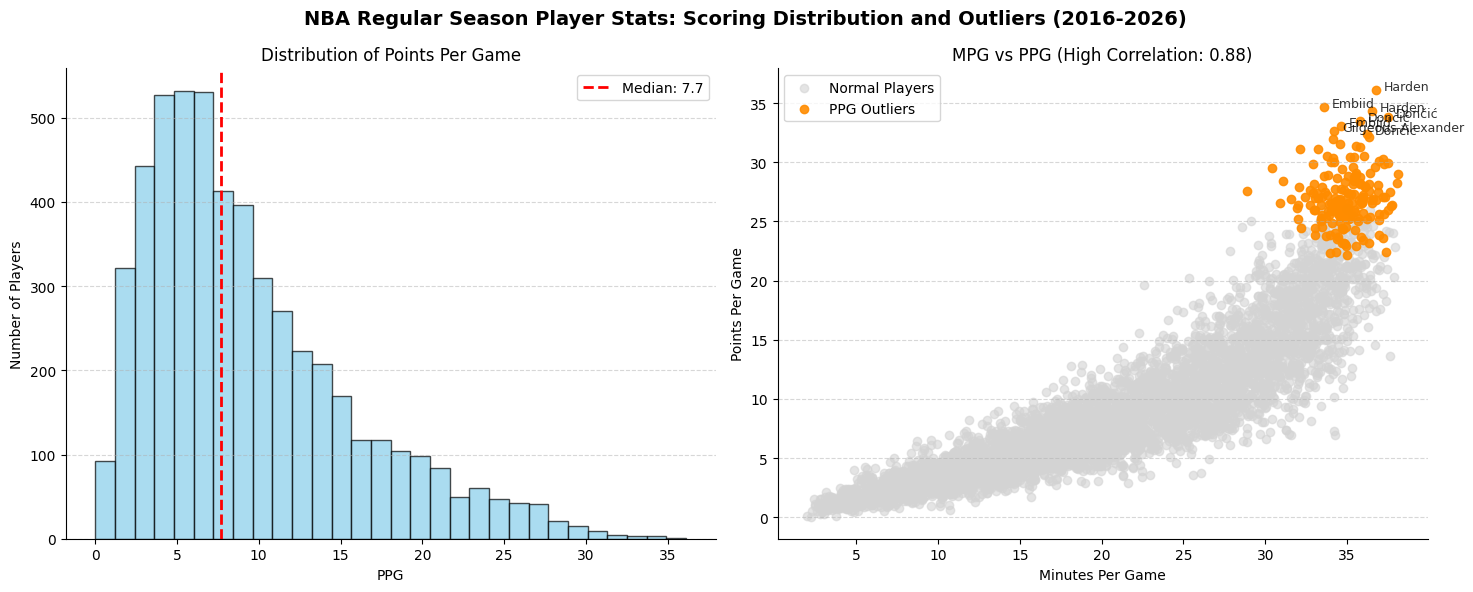

In [ ]:
import matplotlib.pyplot as plt

# Print summary stats
stat_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'plus_minus', 'ts_pct', 'age', 'years_in_nba']
display(df_regular_clean[stat_cols].describe().round(3))

# Compute ppg-mpg correlation
corr_val = df_regular_clean['mpg'].corr(df_regular_clean['ppg'])

# Create plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: Histogram of PPG
axes[0].hist(df_regular_clean['ppg'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
median_ppg = df_regular_clean['ppg'].median()
axes[0].axvline(median_ppg, color='red', linestyle='--', linewidth=2, label=f'Median: {median_ppg:.1f}')
axes[0].set_title('Distribution of Points Per Game')
axes[0].set_xlabel('PPG')
axes[0].set_ylabel('Number of Players')
axes[0].legend()
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].yaxis.grid(True, linestyle='--', alpha=0.5)

# Right: Scatter of MPG vs PPG highlighting outliers
axes[1].scatter(
    df_regular_clean[~df_regular_clean['ppg_outlier']]['mpg'],
    df_regular_clean[~df_regular_clean['ppg_outlier']]['ppg'],
    color='lightgray', alpha=0.6, label='Normal Players'
)

outliers_df = df_regular_clean[df_regular_clean['ppg_outlier']]
axes[1].scatter(
    outliers_df['mpg'], outliers_df['ppg'],
    color='darkorange', alpha=0.9, label='PPG Outliers'
)

# Label select top-tier outliers
for idx, row in outliers_df.sort_values('ppg', ascending=False).head(8).iterrows():
    last_name = row['player_name'].split()[-1]
    axes[1].text(row['mpg'] + 0.5, row['ppg'], last_name, fontsize=9, alpha=0.8)

axes[1].set_title(f'MPG vs PPG (High Correlation: {corr_val:.2f})')
axes[1].set_xlabel('Minutes Per Game')
axes[1].set_ylabel('Points Per Game')
axes[1].legend()
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].yaxis.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('NBA Regular Season Player Stats: Scoring Distribution and Outliers (2016-2026)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### What we found
- **Typical scoring:** The middle value is 7.7 points per game, so most players score fairly little and a few stars score far more.
- **Minutes and points go together:** The correlation between `mpg` and `ppg` is about 0.88, so players who play more minutes score more.
- **Outliers:** After the `gp >= 10` filter, 176 player-seasons are scoring outliers (IQR rule within each season). They are the league's top scorers, and we keep them.

## 5. Playoffs
We repeat the regular-season steps (3B–4) on `df_playoffs`, which was loaded in the first cell.
Playoff samples are much smaller (a team plays 4 to 28 games), so a few thresholds are different:

| Check | Regular season | Playoffs | Why |
|---|---|---|---|
| Minimum games | `gp >= 10` | `gp >= 4` | 4 games = one full series (a sweep). 10 would drop most first-round players |
| Too many games | `gp > 82` | `gp > 28` | 4 rounds × 7 games is the most possible |

Play-in games are **not** in this table: the database has only `regular_season` and `playoffs`, and players whose
teams lost in the play-in (e.g. Stephen Curry and DeMar DeRozan in 2023-24) have no playoff row.

### 5A. Is the playoff data tidy?
Same checks as 3B: one row per player-season, data types, lowercase column names.

In [ ]:
print("--- Dataframe Info ---")
df_playoffs.info()

po_duplicate_pairs = df_playoffs.duplicated(subset=['player_id', 'season']).sum()
print(f"\nNumber of duplicate (player_id, season) pairs: {po_duplicate_pairs}")

po_columns_are_lowercase = df_playoffs.columns.tolist() == [c.lower() for c in df_playoffs.columns]
print(f"Are all columns lowercase? {po_columns_are_lowercase}")
if not po_columns_are_lowercase:
    df_playoffs.columns = [c.lower() for c in df_playoffs.columns]
    print("Converted columns to lowercase.")

--- Dataframe Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2405 entries, 0 to 2404
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   season                  2405 non-null   int64  
 1   player_id               2405 non-null   int64  
 2   player_name             2405 non-null   object 
 3   age                     2405 non-null   float64
 4   years_in_nba            2404 non-null   float64
 5   years_in_nba_estimated  2405 non-null   bool   
 6   gp                      2405 non-null   float64
 7   mpg                     2405 non-null   float64
 8   ppg                     2405 non-null   float64
 9   rpg                     2405 non-null   float64
 10  apg                     2405 non-null   float64
 11  bpg                     2405 non-null   float64
 12  spg                     2405 non-null   float64
 13  plus_minus              2405 non-null   float64
 14  ts_pct           

### What we found
* **Tidiness:** The data is tidy. Each row is one player's stats for one postseason, and each column is one attribute.
* **Duplicates:** There are 0 duplicate (player_id, season) pairs, so each player has at most one playoff record per season.
* **Column names:** The column names are already lowercase and match the regular-season table, so the two tables can be compared directly.

### 5B. Size of the data

In [ ]:
po_rows, po_cols = df_playoffs.shape
print(f"Dataset Shape: {po_rows} rows, {po_cols} columns")
print(f"Season Range: {df_playoffs['season'].min()} to {df_playoffs['season'].max()}")
print(f"Number of Unique Players: {df_playoffs['player_id'].nunique()}")
print("\nRows per Season (expect roughly 200-240: 16 teams x 13-15 players):")
print(df_playoffs['season'].value_counts().sort_index())
print(f"\nGames Played (gp) - Min: {df_playoffs['gp'].min()}, "
      f"Median: {df_playoffs['gp'].median()}, Max: {df_playoffs['gp'].max()}")

# How many playoff players also have a regular-season row that season?
po_in_reg = df_playoffs.merge(df_regular[['player_id', 'season']].drop_duplicates(),
                              on=['player_id', 'season'], how='left', indicator=True)
print("\nPlayoff rows with a matching regular-season row:")
print(po_in_reg['_merge'].map({'both': 'yes', 'left_only': 'no'}).value_counts())

Dataset Shape: 2405 rows, 22 columns
Season Range: 2016 to 2026
Number of Unique Players: 864

Rows per Season (expect roughly 200-240: 16 teams x 13-15 players):
season
2016    215
2017    215
2018    210
2019    212
2020    217
2021    239
2022    217
2023    217
2024    214
2025    219
2026    230
Name: count, dtype: int64

Games Played (gp) - Min: 1.0, Median: 6.0, Max: 24.0

Playoff rows with a matching regular-season row:
_merge
yes    2398
no        7
Name: count, dtype: int64


### What we found
* **Rows and columns:** The raw playoff table has 2,405 rows and 22 columns, about 40% of the size of the regular-season table (5,968 rows). That's expected, because only 16 of 30 teams make the playoffs.
* **Seasons and players:** It covers 2016 to 2026 (2015-16 to 2025-26) with 864 different players. Each postseason has between 210 and 239 players, which fits 16 teams with 13 to 15 players each.
* **Games played:** Players played from 1 to 24 playoff games, and the middle value is 6, compared with 53 in the regular season. Playoff samples are much smaller, which is why we use a lower games cutoff in 5E.
* **Matching regular-season rows:** 2,398 playoff rows have a regular-season row for the same player and season. The other 7 don't, so those players appear only in the playoff table that year.

### 5C. Missing data analysis
Trend columns are expected to be missing more often than in the regular season: a playoff trend needs
**three postseasons in a row**, which only players on consistently good teams have.

In [ ]:
print("--- Missing values per column ---")
print(df_playoffs.isna().sum())

print(f"\nRows with gp == 0: {(df_playoffs['gp'] == 0).sum()}")
print(f"Rows with mpg == 0: {(df_playoffs['mpg'] == 0).sum()}")

po_no_window = (~df_playoffs['full_3yr_window']).sum()
print(f"Rows where full_3yr_window is False: {po_no_window} "
      f"({po_no_window / len(df_playoffs):.1%} of playoff rows)")
print(f"Rows where trend_3yr_ppg is NaN: {df_playoffs['trend_3yr_ppg'].isna().sum()}")

po_non_trend_nans = df_playoffs.drop(columns=[c for c in df_playoffs.columns if 'trend_3yr' in c]).isna().sum()
print("\nMissing values outside the trend columns:")
print(po_non_trend_nans[po_non_trend_nans > 0])
display(df_playoffs[df_playoffs['years_in_nba'].isna()][['season', 'player_id', 'player_name', 'age', 'years_in_nba']])

--- Missing values per column ---
season                       0
player_id                    0
player_name                  0
age                          0
years_in_nba                 1
years_in_nba_estimated       0
gp                           0
mpg                          0
ppg                          0
rpg                          0
apg                          0
bpg                          0
spg                          0
plus_minus                   0
ts_pct                       0
full_3yr_window              0
trend_3yr_ppg             1685
trend_3yr_rpg             1685
trend_3yr_apg             1685
trend_3yr_pm              1685
trend_3yr_mpg             1685
trend_3yr_gp              1685
dtype: int64

Rows with gp == 0: 0
Rows with mpg == 0: 1
Rows where full_3yr_window is False: 1685 (70.1% of playoff rows)
Rows where trend_3yr_ppg is NaN: 1685

Missing values outside the trend columns:
years_in_nba    1
dtype: int64


,season,player_id,player_name,age,years_in_nba
1078,2022,1630492,Luca Vildoza,26.0,NaN


### What we found
* **Trend columns:** 1,685 rows (70%) have no 3-season trend, compared with 37% in the regular season. A playoff trend needs **three postseasons in a row**, and most players' teams don't make the playoffs three years running, so these blanks are expected and left as is.
* **Other missing values:** Only `years_in_nba`, for 1 row: Luca Vildoza in 2021-22. It's handled in 5E.
* **Zero games or minutes:** No row has 0 games, and 1 row has 0 minutes per game. That row is removed by the games filter in 5E.

### 5D. Outliers and suspicious entries
Same IQR rule as 3E (`flag_iqr`, defined earlier), applied within each postseason.

In [ ]:
po_ppg_outlier_series = df_playoffs.groupby('season')['ppg'].transform(flag_iqr)
po_mpg_outlier_series = df_playoffs.groupby('season')['mpg'].transform(flag_iqr)
print(f"Total ppg outliers across all postseasons: {po_ppg_outlier_series.sum()}")
print(f"Total mpg outliers across all postseasons: {po_mpg_outlier_series.sum()}")

print(f"ts_pct outside 0-1: {((df_playoffs['ts_pct'] < 0) | (df_playoffs['ts_pct'] > 1)).sum()}")
print(f"ts_pct == 0: {(df_playoffs['ts_pct'] == 0).sum()}")
print(f"gp > 28: {(df_playoffs['gp'] > 28).sum()}")
po_neg_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp']
print(f"Negative values in stats: {(df_playoffs[po_neg_cols] < 0).sum().sum()}")
print(f"Impossible age or experience: "
      f"{((df_playoffs['age'] < 18) | (df_playoffs['years_in_nba'] < 1)).sum()}")

print("\n--- Top 10 ppg Outliers ---")
display(df_playoffs[po_ppg_outlier_series][['season', 'player_name', 'ppg', 'mpg', 'gp']]
        .sort_values('ppg', ascending=False).head(10))

print("\n--- Examples of Suspicious Rows (gp > 28 or ts_pct == 0 or ts_pct > 1) ---")
display(df_playoffs[(df_playoffs['gp'] > 28) | (df_playoffs['ts_pct'] == 0) | (df_playoffs['ts_pct'] > 1)].head(5))

Total ppg outliers across all postseasons: 64
Total mpg outliers across all postseasons: 0
ts_pct outside 0-1: 23
ts_pct == 0: 154
gp > 28: 0
Negative values in stats: 0
Impossible age or experience: 1

--- Top 10 ppg Outliers ---


,season,player_name,ppg,mpg,gp
1975,2017,Russell Westbrook,37.40,38.90,5.0
1336,2020,Donovan Mitchell,36.29,37.66,7.0
1097,2021,Luka Dončić,35.71,40.15,7.0
663,2023,Kawhi Leonard,34.50,40.19,2.0
1098,2021,Damian Lillard,34.33,41.32,6.0
1099,2021,Kevin Durant,34.25,40.41,12.0
1765,2018,LeBron James,34.00,41.89,22.0
664,2023,Devin Booker,33.73,41.70,11.0
449,2024,Joel Embiid,33.00,41.38,6.0
230,2025,Giannis Antetokounmpo,33.00,37.57,5.0



--- Examples of Suspicious Rows (gp > 28 or ts_pct == 0 or ts_pct > 1) ---


,season,player_id,player_name,age,years_in_nba,years_in_nba_estimated,gp,mpg,ppg,rpg,...,spg,plus_minus,ts_pct,full_3yr_window,trend_3yr_ppg,trend_3yr_rpg,trend_3yr_apg,trend_3yr_pm,trend_3yr_mpg,trend_3yr_gp
109,2026,1642859,Jase Richardson,20.0,1.0,False,1.0,2.95,6.0,0.0,...,0.0,3.00,1.500,False,NaN,NaN,NaN,NaN,NaN,NaN
116,2026,1630192,Zeke Nnaji,25.0,6.0,False,2.0,9.53,5.0,1.5,...,0.5,-1.50,1.078,True,2.61,1.11,0.28,-2.11,6.64,3.67
201,2026,1631120,JD Davison,23.0,4.0,False,2.0,2.62,1.0,1.0,...,0.0,0.50,1.136,False,NaN,NaN,NaN,NaN,NaN,NaN
217,2026,1642346,Ryan Dunn,23.0,2.0,False,4.0,8.45,0.0,1.5,...,0.0,-2.25,0.000,False,NaN,NaN,NaN,NaN,NaN,NaN
218,2026,1642864,Hugo González,20.0,1.0,False,4.0,4.69,0.0,1.0,...,0.0,2.25,0.000,False,NaN,NaN,NaN,NaN,NaN,NaN


### What we found
* **Scoring outliers:** The IQR rule flags 64 player-postseasons for `ppg` and 0 for `mpg`. The highest is Russell Westbrook in 2016-17 (37.40 points per game over 5 games). Several of the top outliers come from short playoff runs (Kawhi Leonard's 34.50 in 2022-23 is over only 2 games), so playoff scoring outliers are partly a small-sample effect. They're real performances, so we keep them and only flag them.
* **Suspicious entries:** 177 rows have a `ts_pct` of 0 or above 1. 153 of them are players with fewer than 4 games and are removed by the `gp >= 4` filter in 5E. The other 24 stay in the table and are marked in `suspicious_entry`. No row has more than 28 games.
* **No other problems:** No stat is negative. 1 row has an impossible age or years in the NBA, and it is removed by the games filter in 5E (the cleaned table's minimum is 1 year).

### 5E. Clean the playoff data
Same steps as 3F, plus filling the missing `years_in_nba` from that player's regular-season row.

In [ ]:
PO_MIN_GP = 4      # one full series

df_playoffs_clean = df_playoffs.copy()
print(f"Initial clean row count: {len(df_playoffs_clean)}")

# 1. Add season_label (same helper as 3F)
df_playoffs_clean['season_label'] = df_playoffs_clean['season'].apply(get_season_label)
print(f"Step 1 - Added season_label. Row count: {len(df_playoffs_clean)}")

# 2. Fill missing years_in_nba from the regular-season table
po_missing_before = df_playoffs_clean['years_in_nba'].isna().sum()
reg_years = df_regular.set_index(['player_id', 'season'])['years_in_nba']
fill_values = pd.Series(
    [reg_years.get((p, s)) for p, s in zip(df_playoffs_clean['player_id'], df_playoffs_clean['season'])],
    index=df_playoffs_clean.index, dtype='float')
df_playoffs_clean['years_in_nba'] = df_playoffs_clean['years_in_nba'].fillna(fill_values)
po_missing_after = df_playoffs_clean['years_in_nba'].isna().sum()
print(f"Step 2 - Filled years_in_nba: {po_missing_before} missing before, {po_missing_after} after.")
if po_missing_after > 0:
    # Undrafted AND no regular-season row that season, so there's nothing to fill from. Leave blank, mark estimated.
    still_missing = df_playoffs_clean['years_in_nba'].isna()
    df_playoffs_clean.loc[still_missing, 'years_in_nba_estimated'] = True
    print("         Still missing (no regular-season row to copy from):")
    display(df_playoffs_clean.loc[still_missing, ['season', 'player_id', 'player_name', 'gp']])
df_playoffs_clean['years_in_nba'] = df_playoffs_clean['years_in_nba'].astype('Int64')

# 3. Filter for gp >= PO_MIN_GP
initial_count = len(df_playoffs_clean)
df_playoffs_clean = df_playoffs_clean[df_playoffs_clean['gp'] >= PO_MIN_GP]
removed_count = initial_count - len(df_playoffs_clean)
print(f"Step 3 - Kept gp >= {PO_MIN_GP}. Removed {removed_count} rows "
      f"({removed_count / initial_count * 100:.2f}% of the table). Row count: {len(df_playoffs_clean)}")

# 4. Add ppg_outlier (recalculated on the filtered table)
df_playoffs_clean['ppg_outlier'] = df_playoffs_clean.groupby('season')['ppg'].transform(flag_iqr)
print(f"Step 4 - Recalculated ppg_outlier. Row count: {len(df_playoffs_clean)}")

# 5. Label suspicious entries
po_susp_mask = (
    (df_playoffs_clean['ts_pct'] < 0) |
    (df_playoffs_clean['ts_pct'] > 1) |
    (df_playoffs_clean['ts_pct'] == 0) |
    (df_playoffs_clean['gp'] > 28)
)
df_playoffs_clean['suspicious_entry'] = po_susp_mask
print(f"Step 5 - Suspicious entry count: {po_susp_mask.sum()}. Row count: {len(df_playoffs_clean)}")

# 6. Trend NaNs are left as is. Same column order as the regular-season table.
df_playoffs_clean = df_playoffs_clean[column_order]
df_playoffs_clean = df_playoffs_clean.sort_values(by=['season', 'ppg'], ascending=[False, False]).reset_index(drop=True)

print(f"\nFinal Clean Shape: {df_playoffs_clean.shape}")
print(f"Total ppg_outliers: {df_playoffs_clean['ppg_outlier'].sum()}")
print(f"Total suspicious_entries: {df_playoffs_clean['suspicious_entry'].sum()}")
print(f"Total rows with full_3yr_window == True: {df_playoffs_clean['full_3yr_window'].sum()}")

Initial clean row count: 2405
Step 1 - Added season_label. Row count: 2405
Step 2 - Filled years_in_nba: 1 missing before, 1 after.
         Still missing (no regular-season row to copy from):


,season,player_id,player_name,gp
1078,2022,1630492,Luca Vildoza,7.0


Step 3 - Kept gp >= 4. Removed 431 rows (17.92% of the table). Row count: 1974
Step 4 - Recalculated ppg_outlier. Row count: 1974
Step 5 - Suspicious entry count: 24. Row count: 1974

Final Clean Shape: (1974, 25)
Total ppg_outliers: 43
Total suspicious_entries: 24
Total rows with full_3yr_window == True: 654


### Result
* **Rows:** The table went from 2,405 rows to 1,974 rows. We removed 431 rows (17.9%) because the player played fewer than 4 playoff games.
* **Columns:** The table has 25 columns, the same ones in the same order as the cleaned regular-season table. We added `season_label`, `ppg_outlier` (43 rows flagged) and `suspicious_entry` (24 rows flagged).
* **Years in NBA:** Luca Vildoza (2021-22) is the only missing value. He has no draft year and no regular-season row that season, so there was nothing to fill it from. It's left blank and marked as estimated.
* **Trend columns:** 654 rows have a full 3-postseason trend. As in the regular season, the trend is calculated before the games filter, so it can include a postseason in which the player played fewer than 4 games.

### 5F. Check against known playoff stat lines
A quick check that the numbers match published playoff stats.

In [ ]:
known_lines = [
    # (player, season, column, expected)
    ("Kawhi Leonard", 2019, "ppg", 30.5),
    ("Kawhi Leonard", 2019, "gp", 24),
    ("LeBron James", 2016, "ppg", 26.3),
    ("LeBron James", 2016, "gp", 21),
]
for name, season, col, expected in known_lines:
    row = df_playoffs_clean[(df_playoffs_clean['player_name'] == name) & (df_playoffs_clean['season'] == season)]
    if row.empty:
        print(f"  ?  {name} {season}: not found")
        continue
    got = row[col].iloc[0]
    status = "OK" if abs(got - expected) <= 0.15 else "CHECK"
    print(f"  {status:5} {name} {season} {col}: got {got}, expected {expected}")

  OK    Kawhi Leonard 2019 ppg: got 30.5, expected 30.5
  OK    Kawhi Leonard 2019 gp: got 24.0, expected 24
  OK    LeBron James 2016 ppg: got 26.29, expected 26.3
  OK    LeBron James 2016 gp: got 21.0, expected 21


### 5G. Save the cleaned playoff data

In [ ]:
po_clean_csv_path = 'data/02-processed/nba_playoffs_cleaned.csv'
df_playoffs_clean.to_csv(po_clean_csv_path, index=False)

df_po_loaded = pd.read_csv(po_clean_csv_path)
print(f"Saved data verification shape: {df_po_loaded.shape}")
display(df_po_loaded.head())

Saved data verification shape: (1974, 25)


,season_label,season,player_id,player_name,age,years_in_nba,years_in_nba_estimated,gp,mpg,ppg,...,ts_pct,full_3yr_window,trend_3yr_ppg,trend_3yr_rpg,trend_3yr_apg,trend_3yr_pm,trend_3yr_mpg,trend_3yr_gp,ppg_outlier,suspicious_entry
0,2025-26,2026,1628973,Jalen Brunson,29.0,8.0,False,19.0,36.92,28.37,...,0.573,True,30.07,3.30,6.84,4.45,38.17,16.67,False,False
1,2025-26,2026,1630595,Cade Cunningham,24.0,5.0,False,14.0,40.82,28.14,...,0.572,False,NaN,NaN,NaN,NaN,NaN,NaN,False,False
2,2025-26,2026,1628983,Shai Gilgeous-Alexander,27.0,8.0,False,15.0,36.28,27.60,...,0.591,True,29.24,5.16,6.95,5.14,37.71,16.00,False,False
3,2025-26,2026,1631094,Paolo Banchero,23.0,4.0,False,7.0,39.02,26.29,...,0.524,True,27.56,8.66,4.83,-2.26,38.64,6.33,False,False
4,2025-26,2026,1628415,Dillon Brooks,30.0,9.0,False,4.0,37.32,26.00,...,0.576,False,NaN,NaN,NaN,NaN,NaN,NaN,False,False


### 5H. Playoff summary statistics
Same summary and plots as section 4.

,ppg,rpg,apg,bpg,spg,mpg,gp,plus_minus,ts_pct,age,years_in_nba
count,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1974.000,1973.0
mean,9.658,3.901,2.020,0.424,0.653,22.120,9.524,-1.272,0.539,27.417,6.838
std,7.709,2.864,2.072,0.480,0.534,11.846,5.440,5.042,0.128,4.265,4.27
min,0.000,0.000,0.000,0.000,0.000,1.140,4.000,-24.000,0.000,19.000,1.0
25%,3.430,1.690,0.570,0.080,0.230,11.712,5.000,-3.800,0.486,24.000,3.0
50%,7.750,3.250,1.260,0.260,0.510,22.655,7.000,-0.670,0.550,27.000,6.0
75%,13.912,5.500,2.750,0.600,1.000,32.900,12.000,1.800,0.607,30.000,10.0
max,37.400,16.330,12.220,4.000,2.800,44.580,24.000,14.410,1.333,41.000,23.0


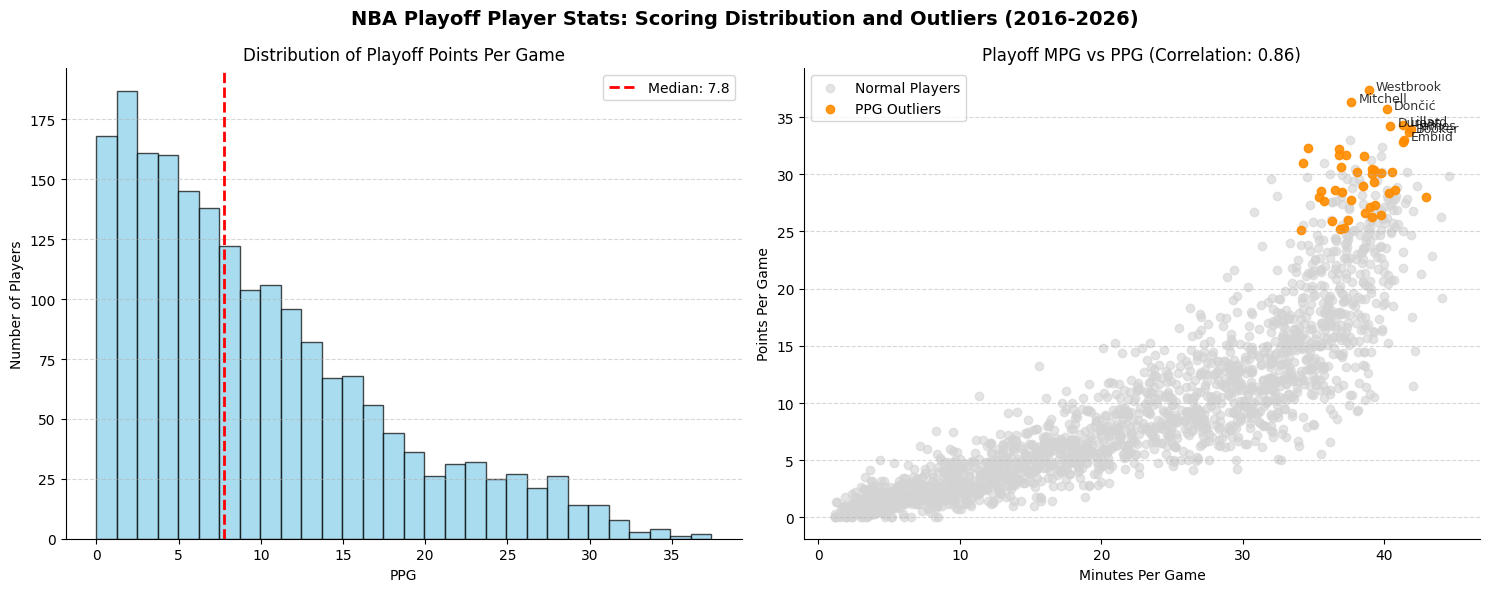

In [ ]:
display(df_playoffs_clean[stat_cols].describe().round(3))

po_corr_val = df_playoffs_clean['mpg'].corr(df_playoffs_clean['ppg'])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].hist(df_playoffs_clean['ppg'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
po_median_ppg = df_playoffs_clean['ppg'].median()
axes[0].axvline(po_median_ppg, color='red', linestyle='--', linewidth=2, label=f'Median: {po_median_ppg:.1f}')
axes[0].set_title('Distribution of Playoff Points Per Game')
axes[0].set_xlabel('PPG')
axes[0].set_ylabel('Number of Players')
axes[0].legend()

po_normal = df_playoffs_clean[~df_playoffs_clean['ppg_outlier']]
po_outliers = df_playoffs_clean[df_playoffs_clean['ppg_outlier']]
axes[1].scatter(po_normal['mpg'], po_normal['ppg'], color='lightgray', alpha=0.6, label='Normal Players')
axes[1].scatter(po_outliers['mpg'], po_outliers['ppg'], color='darkorange', alpha=0.9, label='PPG Outliers')
for _, row in po_outliers.sort_values('ppg', ascending=False).head(8).iterrows():
    axes[1].text(row['mpg'] + 0.5, row['ppg'], row['player_name'].split()[-1], fontsize=9, alpha=0.8)
axes[1].set_title(f'Playoff MPG vs PPG (Correlation: {po_corr_val:.2f})')
axes[1].set_xlabel('Minutes Per Game')
axes[1].set_ylabel('Points Per Game')
axes[1].legend()

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('NBA Playoff Player Stats: Scoring Distribution and Outliers (2016-2026)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### What we found
* **Typical scoring:** The middle value is 7.8 playoff points per game, compared with 7.7 in the cleaned regular-season table. This doesn't mean players score the same in the playoffs: the two tables contain different players (only playoff teams, and coaches shorten their rotations). Section 5I compares the **same** players.
* **Minutes and points go together:** The correlation between `mpg` and `ppg` is 0.86 in the playoffs, compared with 0.88 in the regular season.
* **Outliers:** After the `gp >= 4` filter, 43 player-postseasons are scoring outliers (IQR rule within each postseason). They are the playoffs' top scorers, and we keep them.

### 5I. Regular season vs playoffs: same players
Comparing the two whole tables is misleading, because the playoff table contains only players on good teams.
So we pair each player's playoff row with **his own** regular-season row from the same season, and look at how his stats change.
Both rows must pass their games filter (`gp >= 10` regular season, `gp >= 4` playoffs).

**Points per 36 minutes** separates "scores more because he plays more" from "scores more per minute on the floor".

Player-seasons in both cleaned tables: 1,945


,regular_season_avg,playoffs_avg,avg_change,pct_players_up
mpg,23.557,22.363,-1.194,46.992
ppg,11.110,9.771,-1.339,31.362
rpg,4.324,3.940,-0.383,38.252
apg,2.480,2.042,-0.438,25.604
bpg,0.482,0.429,-0.053,36.504
spg,0.770,0.659,-0.110,32.956
ts_pct,0.572,0.541,-0.031,35.784
plus_minus,1.783,-1.285,-3.068,28.535
pts36,15.960,14.304,-1.656,30.180


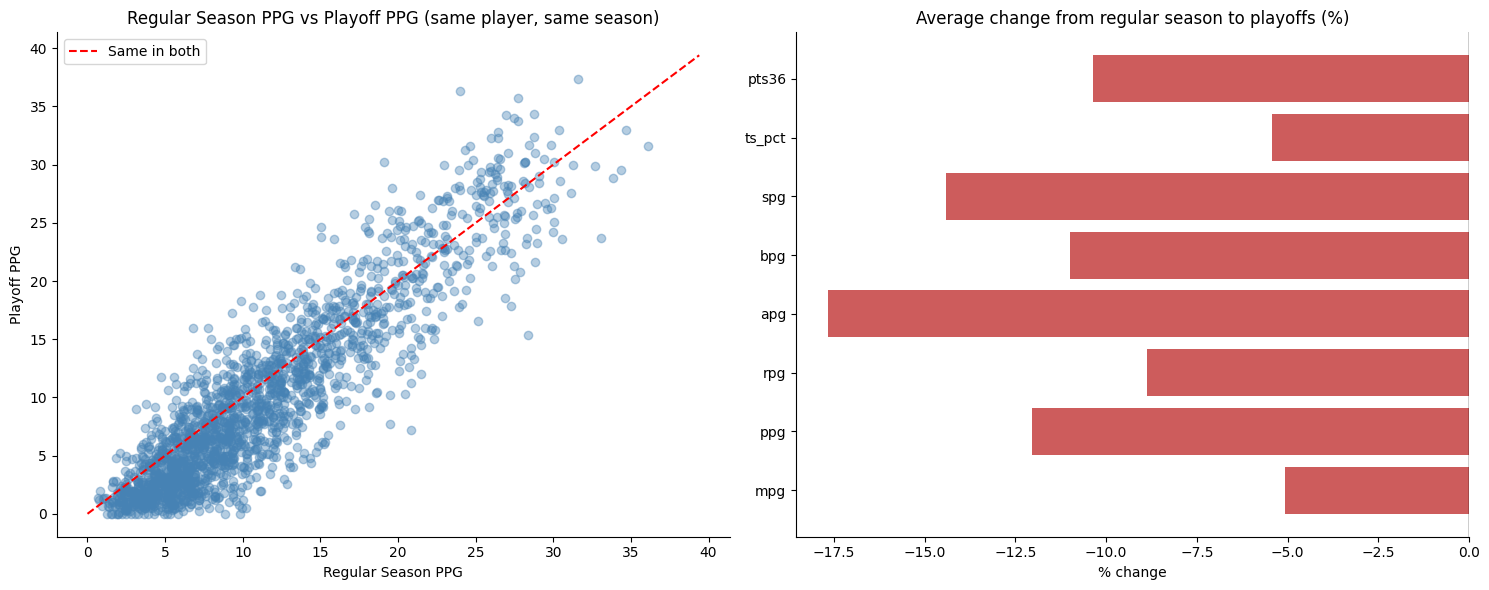

In [ ]:
compare_cols = ['mpg', 'ppg', 'rpg', 'apg', 'bpg', 'spg', 'ts_pct', 'plus_minus']
paired = df_regular_clean.merge(df_playoffs_clean, on=['player_id', 'season'], suffixes=('_rs', '_po'))
for side in ['rs', 'po']:
    paired[f'pts36_{side}'] = paired[f'ppg_{side}'] / paired[f'mpg_{side}'] * 36
compare_cols.append('pts36')

comparison = pd.DataFrame({
    'regular_season_avg': [paired[f'{c}_rs'].mean() for c in compare_cols],
    'playoffs_avg': [paired[f'{c}_po'].mean() for c in compare_cols],
    'avg_change': [(paired[f'{c}_po'] - paired[f'{c}_rs']).mean() for c in compare_cols],
    'pct_players_up': [(paired[f'{c}_po'] > paired[f'{c}_rs']).mean() * 100 for c in compare_cols],
}, index=compare_cols).round(3)
print(f"Player-seasons in both cleaned tables: {len(paired):,}")
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(paired['ppg_rs'], paired['ppg_po'], alpha=0.4, color='steelblue')
lim = max(paired['ppg_rs'].max(), paired['ppg_po'].max()) + 2
axes[0].plot([0, lim], [0, lim], color='red', linestyle='--', label='Same in both')
axes[0].set_title('Regular Season PPG vs Playoff PPG (same player, same season)')
axes[0].set_xlabel('Regular Season PPG')
axes[0].set_ylabel('Playoff PPG')
axes[0].legend()

pct_change = ((comparison['playoffs_avg'] - comparison['regular_season_avg'])
              / comparison['regular_season_avg'].abs() * 100).drop('plus_minus')
axes[1].barh(pct_change.index, pct_change.values,
             color=['seagreen' if v > 0 else 'indianred' for v in pct_change.values])
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Average change from regular season to playoffs (%)')
axes[1].set_xlabel('% change')
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

### What we found
Based on 1,945 player-seasons where the same player passes the games filter in both the regular season and the playoffs:
* **Scoring drops:** Points per game fall from 11.11 to 9.77 on average, and only 31% of players score more in the playoffs.
* **The drop comes from scoring less per minute, not from playing less:** Points per 36 minutes fall from 15.96 to 14.30 (about 10%), while minutes per game fall only from 23.56 to 22.36 (about 5%). 47% of players play more minutes in the playoffs, so rotations shift rather than shrink across the board.
* **Shooting efficiency drops:** True shooting falls from 57.2% to 54.1%, and only 36% of players shoot better. This fits playoff defenses being better and more prepared, since every opponent is a good team.
* **Every other stat also drops on average:** Rebounds fall from 4.32 to 3.94, assists from 2.48 to 2.04, blocks from 0.48 to 0.43 and steals from 0.77 to 0.66.
* **Plus/minus falls from +1.78 to −1.28:** In the regular season these players are mostly on good teams beating weaker ones. In the playoffs, half of all games are losses against other good teams. So this change mostly reflects the competition, not the player.

**Caveat:** this only covers players whose teams made the playoffs, so it describes how good-team players change, not every player.

### 5J. Notes on how the data was built
Points to keep in mind when using either cleaned table:
* **Missing trend values are left blank on purpose.** A trend can only be calculated when a player has 3 seasons in a row, so it's blank for rookies, players who missed a season, and, in the playoffs, anyone whose team didn't make three straight postseasons. That's **37% of the regular-season table and 70% of the raw playoff table** (1,685 of 2,405 rows; after cleaning, 654 of 1,974 playoff rows have a trend). We don't fill these values: filling with 0 or an average would invent a history the player doesn't have, and dropping the rows would throw away real playoff stats. The `full_3yr_window` column marks which rows have a trend, so any analysis of trends should filter to `full_3yr_window == True`.
* **`trend_3yr_*` columns are 3-season averages, not trends.** They're the average of this season and the two before it, so they smooth out a player's level but don't show whether he's improving or declining. A player going 30 → 25 → 20 PPG and one going 20 → 25 → 30 both get 25. To measure direction, use the change per season (in DuckDB: `REGR_SLOPE(ppg, season) OVER w3`).
* **Playoff trends use playoff seasons only** and need three postseasons in a row, so most are blank.
* **`plus_minus` is on-court plus/minus per game**, not Box Plus/Minus (BPM). It depends on teammates and opponents. The database has no BPM; `openrapm` has an adjusted impact rating, but only for the regular season.
* **`years_in_nba`** is counted from the draft year. It overcounts players who were drafted but joined the league later (draft-and-stash picks).
* **Traded players** have one combined row per season in the source table (checked with Luka Dončić, 2024-25: one row, 50 games), so their stats are not double-counted. Their `gp` can go above 82 (e.g. Mikal Bridges, 83 in 2022-23) because they can join a team that has more games left. That's real, not an error.
* **Play-in games** are in neither table. The database has only `regular_season` and `playoffs`, and Curry and DeRozan (who lost in the 2023-24 play-in) have no playoff row.